# Сверточная сеть
В этом ноутбуке мы расширим предыдущий и создадим первую сверточную сеть

In [71]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [72]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist)


In [73]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

In [74]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [75]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

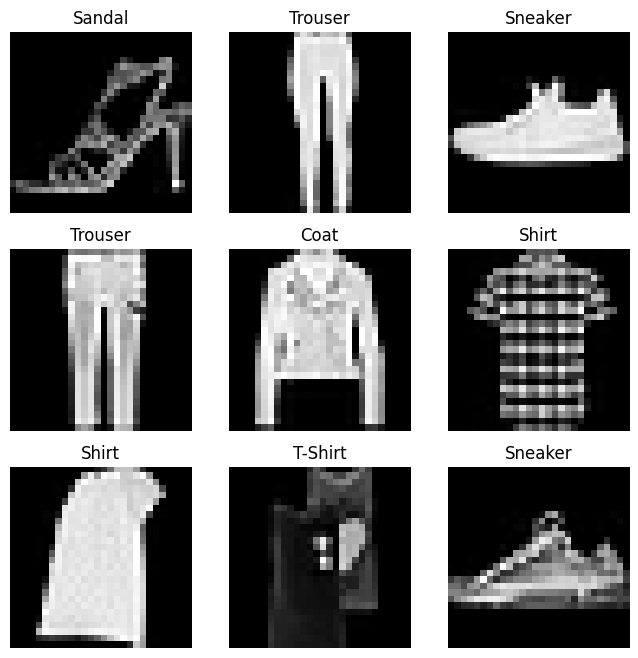

In [76]:
plot_samples(train_data, labels_map, cols=3, rows=3)

In [77]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


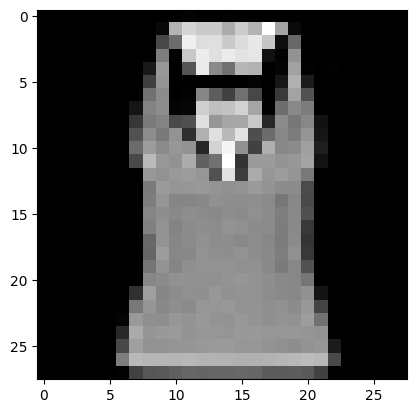

Label: 0


In [78]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [79]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cuda device


Теперь создадим класс модели и интстанциируем её. В данном случае это простая сверточная сеть: изображение проходит через блоки из сверток `nn.Conv2d` с batch-нормализацией (`nn.BatchNorm2d`) и активацией (`nn.ReLU`), а затем карта признаков разворачивается в вектор и подается в линейную голову `nn.Linear`, выдающую логиты для 10 классов. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.


### Архитектура модели

Схема ниже показывает названия слоев и размер выхода каждого слоя (для одного изображения):

![diagram](./images/simple_cnn.png)

In [80]:
class NeuralNetwork(nn.Module):
    """Базовая CNN: после свёрток признаки разворачиваются в один вектор."""
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.head = nn.Linear(16 * 28 * 28, 10)

    def forward(self, x):
        x = self.base(x)
        x = x.view(x.size(0), -1)
        logits = self.head(x)
        return logits


class NN_AvgPool(nn.Module):
    """CNN с Global Average Pooling вместо разворачивания карты признаков."""
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        # Для каждого из 16 каналов оставляем одно среднее значение.
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Linear(16, 10)

    def forward(self, x):
        x = self.base(x)
        x = self.pool(x)
        x = torch.flatten(x, start_dim=1)
        return self.head(x)


model = NeuralNetwork().to(device)
print(model)
print(f"Количество параметров модели с pooling: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

model_ap = NN_AvgPool().to(device)
print(model_ap)
print(f"Количество параметров модели с pooling: {sum(p.numel() for p in model_ap.parameters() if p.requires_grad):,}")

NeuralNetwork(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (head): Linear(in_features=12544, out_features=10, bias=True)
)
Количество параметров модели с pooling: 130,490
NN_AvgPool(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (head): Linear(in_features=16, out_feat

Часто вместо решейпа перед головой используют пулинг. Это специальный слой, который накладывается на вход и позволяет получить его преобразование (max, avg) без весов:
![alt text](.\images\max_pool.png "Stride=1, padding=0")

Если сделать MaxPool2d или AvgPool2d с размером ядра, равным размеру входа, то получится вектор такого же размера, как исходное число каналов. Однако, все равно придется добавить дополнительное измерение.

**Задание**: Измените модель, используя MaxPool или AvgPool вместо view(). Сравните результаты.



**Решение задания.** В модели `NN_AvgPool` выше используется `nn.AdaptiveAvgPool2d((1, 1))`: для каждого канала карта признаков размера `28 × 28` преобразуется в одно среднее значение. Поэтому на вход `nn.Linear` поступает вектор из 16 чисел, а не `16 × 28 × 28`.

Альтернативно можно использовать `nn.AdaptiveMaxPool2d((1, 1))`, который оставляет максимум в каждом канале. Для сравнения сохранена базовая модель `NeuralNetwork`, в которой признаки разворачиваются без пулинга.

**Сравнение:** у варианта с Global Average Pooling значительно меньше параметров в классификационной голове (16 × 10 вместо 16 × 28 × 28 × 10). Это обычно снижает риск переобучения и потребление памяти, но может привести к потере части пространственной информации, что может сильно повлиять на точность. Фактические Accuracy, Precision и Recall нужно сравнить после обучения моделей на одинаковом числе эпох и с одинаковыми настройками. **(Сравнение в конце ноутбука)**

Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [81]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [82]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    total_loss = 0.0

    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)
        
        preds = model(inputs)
        loss = loss_fn(preds, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * inputs.size(0)

        if batch_idx % 100 == 0:
            current = (batch_idx + 1) * len(inputs)
            print(f"loss: {loss.item():>7f}  [{current:>5d}/{size:>5d}]")

    average_loss = total_loss / size
    print(f"Средний train loss: {average_loss:.6f}")
    return average_loss

In [83]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    model.eval()
    test_loss = 0.0
    num_correct = 0
    num_classes = 10
    confusion = torch.zeros(num_classes, num_classes, dtype=torch.long)

    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            loss = loss_fn(logits, targets)

            test_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            num_correct += (predictions == targets).sum().item()

            # Строки — истинные классы, столбцы — предсказанные.
            indices = targets * num_classes + predictions
            confusion += torch.bincount(
                indices.cpu(), minlength=num_classes * num_classes
            ).reshape(num_classes, num_classes)

    test_loss /= size
    accuracy = num_correct / size

    # Для каждого класса считаем TP, FP и FN.
    confusion = confusion.float()
    true_positive = confusion.diag()
    false_positive = confusion.sum(dim=0) - true_positive
    false_negative = confusion.sum(dim=1) - true_positive

    precision_per_class = true_positive / (true_positive + false_positive).clamp(min=1)
    recall_per_class = true_positive / (true_positive + false_negative).clamp(min=1)

    # Macro average: одинаковый вес у каждого из 10 классов.
    precision = precision_per_class.mean().item()
    recall = recall_per_class.mean().item()

    print(
        f"Test: Accuracy: {100 * accuracy:.2f}% | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"Test loss: {test_loss:.6f}"
    )

    return {
        "loss": test_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall
    }

**Решение задания: метрики Precision и Recall.**

Метрики рассчитываются отдельно для каждого из 10 классов, затем усредняются .

- **Precision** = TP / (TP + FP): какая доля объектов, предсказанных как данный класс, действительно к нему относится.
- **Recall** = TP / (TP + FN): какую долю объектов данного класса модель смогла найти.

Здесь TP — верные предсказания класса, FP — объекты других классов, ошибочно отнесённые к нему, FN — объекты этого класса, отнесённые к другим. Деление на ноль обрабатывается безопасно. Реализация находится в функции `test()` выше.

In [84]:
epochs = 10
best_test_loss = float("inf")
history = []

for t in range(epochs):
    print(f"Epoch {t+1}\\n-------------------------------")
    train_loss = train(train_dataloader, model, loss_fn, optimizer)
    metrics = test(test_dataloader, model, loss_fn)
    history.append({"epoch": t + 1, "train_loss": train_loss, **metrics})

    # Сохраняем веса модели с наименьшей ошибкой на тестовой выборке.
    if metrics["loss"] < best_test_loss:
        best_test_loss = metrics["loss"]
        torch.save(model.state_dict(), "best_cnn_model.pth")
        print("Сохранена модель с лучшим test loss.")

print(f"Минимальный test loss: {best_test_loss:.6f}")

Epoch 1\n-------------------------------
loss: 2.375450  [   64/60000]
loss: 0.549984  [ 6464/60000]
loss: 0.542075  [12864/60000]
loss: 0.690736  [19264/60000]
loss: 0.439864  [25664/60000]
loss: 0.461040  [32064/60000]
loss: 0.481564  [38464/60000]
loss: 0.489675  [44864/60000]
loss: 0.533411  [51264/60000]
loss: 0.337108  [57664/60000]
Средний train loss: 0.571880
Test: Accuracy: 84.37% | Precision: 0.8420 | Recall: 0.8437 | Test loss: 0.442559
Сохранена модель с лучшим test loss.
Epoch 2\n-------------------------------
loss: 0.264569  [   64/60000]
loss: 0.335920  [ 6464/60000]
loss: 0.262793  [12864/60000]
loss: 0.248961  [19264/60000]
loss: 0.445924  [25664/60000]
loss: 0.481032  [32064/60000]
loss: 0.402023  [38464/60000]
loss: 0.415139  [44864/60000]
loss: 0.502232  [51264/60000]
loss: 0.284017  [57664/60000]
Средний train loss: 0.388033
Test: Accuracy: 86.48% | Precision: 0.8640 | Recall: 0.8648 | Test loss: 0.390988
Сохранена модель с лучшим test loss.
Epoch 3\n-------------

Осталось сохранить модель для дальнейшего использования.

Сохраняем `state_dict` — обученные веса модели. Архитектура класса `NeuralNetwork` должна быть определена при загрузке весов. В цикле обучения выше автоматически сохраняется версия с минимальным test loss.

In [85]:
# Сохраняем итоговые веса (последняя эпоха).
torch.save(model.state_dict(), "simple_cnn_model.pth")

print("Модель сохранена в simple_cnn_model.pth; лучшая версия — best_cnn_model.pth.")

Модель сохранена в simple_cnn_model.pth; лучшая версия — best_cnn_model.pth.


**Решение задания: собственная модель CNN.**

Предлагаю архитектуру CNN из трёх свёрточных блоков, адаптированную для классификации изображений Fashion-MNIST. В первых двух блоках используются по два свёрточных слоя с BatchNorm и ReLU, после которых применяется MaxPool2d для уменьшения пространственного размера карт признаков. Третий блок позволяет извлекать более сложные признаки без дополнительного уменьшения размерности. В классификаторе используется Flatten для сохранения пространственной информации, полносвязный слой и Dropout для снижения риска переобучения.

In [86]:

import torch
import torch.nn as nn


class CustomCNN(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            # Первый блок: 1 x 28 x 28 -> 32 x 28 x 28
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),  # 32 x 14 x 14

            # Второй блок: 32 x 14 x 14 -> 64 x 14 x 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),  # 64 x 7 x 7

            # Третий блок: 64 x 7 x 7 -> 128 x 7 x 7
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


custom_model = CustomCNN().to(device)

print(custom_model)

print(
    "Количество обучаемых параметров:",
    f"{sum(p.numel() for p in custom_model.parameters() if p.requires_grad):,}"
)


CustomCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128

### Cравнение базовой, Pooling, Custom моделей

В следующей ячейке можно провести честное сравнение вариантов  архитектуры. Модели обучаются с одинаковым оптимизатором и на тех же загрузчиках данных.

In [87]:

comparison_epochs = 10
comparison_results = {}

for model_name, comparison_model in [
    ("No Pooling", NeuralNetwork().to(device)),
    ("Pooling", NN_AvgPool().to(device)),
    ("Custom", CustomCNN().to(device))
]:
    print(f"\n===== {model_name} =====")
    comparison_optimizer = torch.optim.Adam(comparison_model.parameters(), lr=1e-3)

    for epoch in range(comparison_epochs):
        print(f"Эпоха {epoch + 1}/{comparison_epochs}")
        train(train_dataloader, comparison_model, loss_fn, comparison_optimizer)

    comparison_results[model_name] = test(test_dataloader, comparison_model, loss_fn)

print("\nИтоговое сравнение:")
for model_name, result in comparison_results.items():
    print(
        f"{model_name}: accuracy={result['accuracy']:.4f}, "
        f"precision={result['precision']:.4f}, "
        f"recall={result['recall']:.4f}, loss={result['loss']:.6f}"
    )


===== No Pooling =====
Эпоха 1/10
loss: 2.349123  [   64/60000]
loss: 0.658260  [ 6464/60000]
loss: 0.480808  [12864/60000]
loss: 0.158562  [19264/60000]
loss: 0.305687  [25664/60000]
loss: 0.237621  [32064/60000]
loss: 0.399561  [38464/60000]
loss: 0.109296  [44864/60000]
loss: 0.184602  [51264/60000]
loss: 0.236954  [57664/60000]
Средний train loss: 0.391971
Эпоха 2/10
loss: 0.166846  [   64/60000]
loss: 0.196056  [ 6464/60000]
loss: 0.262443  [12864/60000]
loss: 0.132351  [19264/60000]
loss: 0.169302  [25664/60000]
loss: 0.145873  [32064/60000]
loss: 0.180063  [38464/60000]
loss: 0.133435  [44864/60000]
loss: 0.136931  [51264/60000]
loss: 0.225255  [57664/60000]
Средний train loss: 0.241111
Эпоха 3/10
loss: 0.176973  [   64/60000]
loss: 0.182764  [ 6464/60000]
loss: 0.161499  [12864/60000]
loss: 0.292918  [19264/60000]
loss: 0.223683  [25664/60000]
loss: 0.106748  [32064/60000]
loss: 0.183564  [38464/60000]
loss: 0.130134  [44864/60000]
loss: 0.179985  [51264/60000]
loss: 0.312515 

### Вывод по сравнению архитектур CNN

* Точные числа могут отличаться от запуска к запуску

Наилучшие результаты показала **Custom**: Accuracy составила 92.39%, Precision — 92.48%, Recall — 92.39%, а Loss — 0.243876. Таким образом, она превзошла остальные архитектуры по всем представленным метрикам.

Модель **No Pooling** заняла второе место с Accuracy 90.32%. Её результаты также достаточно высокие, однако собственная архитектура Custom обеспечила улучшение точности на 2.07 процентного пункта и снижение функции потерь.

Модель **Pooling** показала наихудший результат: Accuracy составила 67.81%, а Loss — 0.843113. Это может быть связано с потерей значительной части пространственной информации при уменьшении размерности признаковых карт.